<a href="https://colab.research.google.com/github/maryamashraf6565-star/house_price_detector/blob/main/House_pricing_Detector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Imports will be needed in my project
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sklearn

In [11]:
#Loading the dataset as pandas dataFrame
house_df=pd.read_csv('/content/NY-House-Dataset.csv',encoding='latin-1')
house_df

,BROKERTITLE,TYPE,PRICE,BEDS,BATH,PROPERTYSQFT,ADDRESS,STATE,MAIN_ADDRESS,ADMINISTRATIVE_AREA_LEVEL_2,LOCALITY,SUBLOCALITY,STREET_NAME,LONG_NAME,FORMATTED_ADDRESS,LATITUDE,LONGITUDE
0,Brokered by Douglas Elliman -111 Fifth Ave,Condo for sale,315000,2,2.000000,1400.000000,2 E 55th St Unit 803,"New York, NY 10022","2 E 55th St Unit 803New York, NY 10022",New York County,New York,Manhattan,East 55th Street,Regis Residence,"Regis Residence, 2 E 55th St #803, New York, N...",40.761255,-73.974483
1,Brokered by Serhant,Condo for sale,195000000,7,10.000000,17545.000000,Central Park Tower Penthouse-217 W 57th New Yo...,"New York, NY 10019",Central Park Tower Penthouse-217 W 57th New Yo...,United States,New York,New York County,New York,West 57th Street,"217 W 57th St, New York, NY 10019, USA",40.766393,-73.980991
2,Brokered by Sowae Corp,House for sale,260000,4,2.000000,2015.000000,620 Sinclair Ave,"Staten Island, NY 10312","620 Sinclair AveStaten Island, NY 10312",United States,New York,Richmond County,Staten Island,Sinclair Avenue,"620 Sinclair Ave, Staten Island, NY 10312, USA",40.541805,-74.196109
3,Brokered by COMPASS,Condo for sale,69000,3,1.000000,445.000000,2 E 55th St Unit 908W33,"Manhattan, NY 10022","2 E 55th St Unit 908W33Manhattan, NY 10022",United States,New York,New York County,New York,East 55th Street,"2 E 55th St, New York, NY 10022, USA",40.761398,-73.974613
4,Brokered by Sotheby's International Realty - E...,Townhouse for sale,55000000,7,2.373861,14175.000000,5 E 64th St,"New York, NY 10065","5 E 64th StNew York, NY 10065",United States,New York,New York County,New York,East 64th Street,"5 E 64th St, New York, NY 10065, USA",40.767224,-73.969856
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4796,Brokered by COMPASS,Co-op for sale,599000,1,1.000000,2184.207862,222 E 80th St Apt 3A,"Manhattan, NY 10075","222 E 80th St Apt 3AManhattan, NY 10075",New York,New York County,New York,Manhattan,222,"222 E 80th St #3a, New York, NY 10075, USA",40.774350,-73.955879
4797,Brokered by Mjr Real Estate Llc,Co-op for sale,245000,1,1.000000,2184.207862,97-40 62 Dr Unit Lg,"Rego Park, NY 11374","97-40 62 Dr Unit LgRego Park, NY 11374",United States,New York,Queens County,Queens,62nd Drive,"97-40 62nd Dr, Rego Park, NY 11374, USA",40.732538,-73.860152
4798,Brokered by Douglas Elliman - 575 Madison Ave,Co-op for sale,1275000,1,1.000000,2184.207862,427 W 21st St Unit Garden,"New York, NY 10011","427 W 21st St Unit GardenNew York, NY 10011",United States,New York,New York County,New York,West 21st Street,"427 W 21st St, New York, NY 10011, USA",40.745882,-74.003398
4799,Brokered by E Realty International Corp,Condo for sale,598125,2,1.000000,655.000000,91-23 Corona Ave Unit 4G,"Elmhurst, NY 11373","91-23 Corona Ave Unit 4GElmhurst, NY 11373",New York,Queens County,Queens,Flushing,91-23,"91-23 Corona Ave. #4b, Flushing, NY 11373, USA",40.742770,-73.872752


In [6]:
print(house_df.shape)

(4801, 17)


In [14]:
print(house_df.isnull().sum())

BROKERTITLE                    0
TYPE                           0
PRICE                          0
BEDS                           0
BATH                           0
PROPERTYSQFT                   0
ADDRESS                        0
STATE                          0
MAIN_ADDRESS                   0
ADMINISTRATIVE_AREA_LEVEL_2    0
LOCALITY                       0
SUBLOCALITY                    0
STREET_NAME                    0
LONG_NAME                      0
FORMATTED_ADDRESS              0
LATITUDE                       0
LONGITUDE                      0
dtype: int64


In [17]:
print(house_df['PRICE'].describe()) # there is over flow !!!

count    4.801000e+03
mean     2.356940e+06
std      3.135525e+07
min      2.494000e+03
25%      4.990000e+05
50%      8.250000e+05
75%      1.495000e+06
max      2.147484e+09
Name: PRICE, dtype: float64


In [20]:
house_df= house_df[house_df['PRICE'] < 100_000_000]
house_df

,BROKERTITLE,TYPE,PRICE,BEDS,BATH,PROPERTYSQFT,ADDRESS,STATE,MAIN_ADDRESS,ADMINISTRATIVE_AREA_LEVEL_2,LOCALITY,SUBLOCALITY,STREET_NAME,LONG_NAME,FORMATTED_ADDRESS,LATITUDE,LONGITUDE
0,Brokered by Douglas Elliman -111 Fifth Ave,Condo for sale,315000,2,2.000000,1400.000000,2 E 55th St Unit 803,"New York, NY 10022","2 E 55th St Unit 803New York, NY 10022",New York County,New York,Manhattan,East 55th Street,Regis Residence,"Regis Residence, 2 E 55th St #803, New York, N...",40.761255,-73.974483
2,Brokered by Sowae Corp,House for sale,260000,4,2.000000,2015.000000,620 Sinclair Ave,"Staten Island, NY 10312","620 Sinclair AveStaten Island, NY 10312",United States,New York,Richmond County,Staten Island,Sinclair Avenue,"620 Sinclair Ave, Staten Island, NY 10312, USA",40.541805,-74.196109
3,Brokered by COMPASS,Condo for sale,69000,3,1.000000,445.000000,2 E 55th St Unit 908W33,"Manhattan, NY 10022","2 E 55th St Unit 908W33Manhattan, NY 10022",United States,New York,New York County,New York,East 55th Street,"2 E 55th St, New York, NY 10022, USA",40.761398,-73.974613
4,Brokered by Sotheby's International Realty - E...,Townhouse for sale,55000000,7,2.373861,14175.000000,5 E 64th St,"New York, NY 10065","5 E 64th StNew York, NY 10065",United States,New York,New York County,New York,East 64th Street,"5 E 64th St, New York, NY 10065, USA",40.767224,-73.969856
5,Brokered by Sowae Corp,House for sale,690000,5,2.000000,4004.000000,584 Park Pl,"Brooklyn, NY 11238","584 Park PlBrooklyn, NY 11238",United States,New York,Kings County,Brooklyn,Park Place,"584 Park Pl, Brooklyn, NY 11238, USA",40.674363,-73.958725
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4796,Brokered by COMPASS,Co-op for sale,599000,1,1.000000,2184.207862,222 E 80th St Apt 3A,"Manhattan, NY 10075","222 E 80th St Apt 3AManhattan, NY 10075",New York,New York County,New York,Manhattan,222,"222 E 80th St #3a, New York, NY 10075, USA",40.774350,-73.955879
4797,Brokered by Mjr Real Estate Llc,Co-op for sale,245000,1,1.000000,2184.207862,97-40 62 Dr Unit Lg,"Rego Park, NY 11374","97-40 62 Dr Unit LgRego Park, NY 11374",United States,New York,Queens County,Queens,62nd Drive,"97-40 62nd Dr, Rego Park, NY 11374, USA",40.732538,-73.860152
4798,Brokered by Douglas Elliman - 575 Madison Ave,Co-op for sale,1275000,1,1.000000,2184.207862,427 W 21st St Unit Garden,"New York, NY 10011","427 W 21st St Unit GardenNew York, NY 10011",United States,New York,New York County,New York,West 21st Street,"427 W 21st St, New York, NY 10011, USA",40.745882,-74.003398
4799,Brokered by E Realty International Corp,Condo for sale,598125,2,1.000000,655.000000,91-23 Corona Ave Unit 4G,"Elmhurst, NY 11373","91-23 Corona Ave Unit 4GElmhurst, NY 11373",New York,Queens County,Queens,Flushing,91-23,"91-23 Corona Ave. #4b, Flushing, NY 11373, USA",40.742770,-73.872752


In [22]:
house_df = house_df[house_df['PROPERTYSQFT'] != 2184.207862]
house_df = house_df[house_df['BATH'] != 2.3738608579684373]
print("After placeholder filter:", house_df.shape)

After placeholder filter: (3002, 17)


In [25]:
house_df = house_df.dropna(subset=['PRICE', 'BEDS', 'BATH', 'PROPERTYSQFT'])
#house_df = house_df[house_df['PROPERTYSQFT'] > 0]
#house_df = house_df.drop_duplicates()
print("After nulls + duplicates:", house_df.shape)

After nulls + duplicates: (2876, 17)


In [28]:
print(house_df['TYPE'].value_counts())
print(house_df['PRICE'].describe())

TYPE
Condo for sale        723
Co-op for sale        668
House for sale        653
Townhouse for sale    181
Name: count, dtype: int64
count    2.225000e+03
mean     1.942407e+06
std      3.987299e+06
min      6.000000e+04
25%      4.740000e+05
50%      7.500000e+05
75%      1.625000e+06
max      5.600000e+07
Name: PRICE, dtype: float64


In [36]:
# Features: the numeric columns that actually describe a property
feature_cols = ['BEDS', 'BATH', 'PROPERTYSQFT', 'LATITUDE', 'LONGITUDE']
X = house_df[feature_cols].copy()

y = np.log1p(house_df['PRICE'])

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\ny range:", round(y.min(), 2), "to", round(y.max(),2))
print("Price range:", house_df['PRICE'].min(), "to", house_df['PRICE'].max())

X shape: (2225, 5)
y shape: (2225,)

y range: 11.0 to 17.84
Price range: 60000 to 56000000


In [38]:
X.describe().round(2)

,BEDS,BATH,PROPERTYSQFT,LATITUDE,LONGITUDE
count,2225.00,2225.00,2225.00,2225.00,2225.00
mean,2.85,2.19,1771.05,40.71,-73.95
std,1.76,1.47,1741.96,0.09,0.10
min,1.00,1.00,250.00,40.50,-74.25
25%,2.00,1.00,857.00,40.63,-74.00
50%,3.00,2.00,1248.00,40.72,-73.96
75%,3.00,2.00,1987.00,40.77,-73.89
max,32.00,16.00,33000.00,40.91,-73.70


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape)
print("Test: ", X_test.shape)

Train: (1780, 5)
Test:  (445, 5)


In [53]:
# One-hot encode SUBLOCALITY; drop_first avoids collinearity
boroughs = pd.get_dummies(house_df['SUBLOCALITY'], prefix='boro', drop_first=True)
print(boroughs)
print(house_df['SUBLOCALITY'])
# Align with the same split
boroughs_train, boroughs_test = train_test_split(
    boroughs, test_size=0.2, random_state=42
)

print("Borough features:", boroughs.shape)
print("Train:", boroughs_train.shape, "Test:", boroughs_test.shape)

      boro_Brooklyn  boro_Brooklyn Heights  ...  boro_Staten Island  boro_The Bronx
0             False                  False  ...               False           False
2             False                  False  ...               False           False
3             False                  False  ...               False           False
5             False                  False  ...               False           False
7             False                  False  ...               False           False
...             ...                    ...  ...                 ...             ...
4781           True                  False  ...               False           False
4787          False                  False  ...               False           False
4794          False                  False  ...               False           False
4799          False                  False  ...               False           False
4800           True                  False  ...               False         

In [60]:

feature_sets = {
    'M1: Area only':      ['PROPERTYSQFT'],
    'M2: + Beds + Baths': ['PROPERTYSQFT', 'BEDS', 'BATH'],
    'M3: + Geo':          ['PROPERTYSQFT', 'BEDS', 'BATH', 'LATITUDE', 'LONGITUDE'],
}

results = []

for name, cols in feature_sets.items():
    model = LinearRegression().fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])
    results.append({
        'Model': name,
        'R²': r2_score(y_test, pred),
        'MAE (log)': mean_absolute_error(y_test, pred),
        'MAE ($)': np.mean(np.abs(np.expm1(pred) - np.expm1(y_test))),
    })

X4_train = pd.concat([X_train, boroughs_train], axis=1)
X4_test  = pd.concat([X_test,  boroughs_test],  axis=1)
m4 = LinearRegression().fit(X4_train, y_train)
pred4 = m4.predict(X4_test)

results.append({
    'Model': 'M4: + Borough',
    'R²': r2_score(y_test, pred4),
    'MAE (log)': mean_absolute_error(y_test, pred4),
    'MAE ($)': np.mean(np.abs(np.expm1(pred4) - np.expm1(y_test))),
})

In [61]:
results_df = pd.DataFrame(results).set_index('Model').round(3)
print(results_df)

                       R²  MAE (log)      MAE ($)
Model                                            
M1: Area only       0.538      0.576  1444568.788
M2: + Beds + Baths  0.608      0.535  1357391.984
M3: + Geo           0.625      0.519  1337851.116
M4: + Borough       0.785      0.395  1039613.778


In [62]:
m3 = LinearRegression().fit(X_train[feature_sets['M3: + Geo']], y_train)
coefs = pd.DataFrame({
    'Feature': feature_sets['M3: + Geo'],
    'Coefficient': m3.coef_.round(4),
})
print(coefs)
print("\nIntercept:", round(m3.intercept_, 4))

        Feature  Coefficient
0  PROPERTYSQFT       0.0002
1          BEDS      -0.0399
2          BATH       0.3615
3      LATITUDE       1.4598
4     LONGITUDE      -1.7925

Intercept: -179.2575


In [63]:
numeric_cols = ['PROPERTYSQFT', 'BEDS', 'BATH', 'LATITUDE', 'LONGITUDE']
print(X[numeric_cols].corr().round(2))

              PROPERTYSQFT  BEDS  BATH  LATITUDE  LONGITUDE
PROPERTYSQFT          1.00  0.67  0.82      0.03      -0.12
BEDS                  0.67  1.00  0.76     -0.01      -0.08
BATH                  0.82  0.76  1.00      0.03      -0.12
LATITUDE              0.03 -0.01  0.03      1.00       0.56
LONGITUDE            -0.12 -0.08 -0.12      0.56       1.00


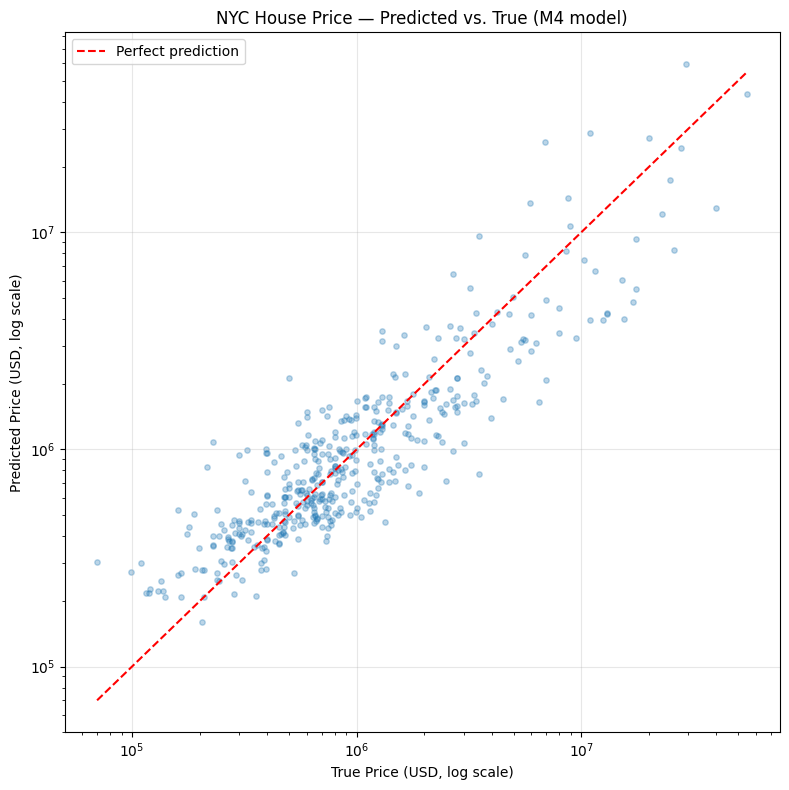

In [66]:
# Predictions from M4 (best model)
pred_log = m4.predict(X4_test)
pred_usd = np.expm1(pred_log)
true_usd = np.expm1(y_test)

plt.figure(figsize=(8, 8))
plt.scatter(true_usd, pred_usd, alpha=0.3, s=15)
plt.plot([true_usd.min(), true_usd.max()],
         [true_usd.min(), true_usd.max()],
         'r--', label='Perfect prediction')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('True Price (USD, log scale)')
plt.ylabel('Predicted Price (USD, log scale)')
plt.title('NYC House Price — Predicted vs. True (M4 model)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('predicted_vs_true.png', dpi=120, bbox_inches='tight')
plt.show()